# Notebook 2 - Solver Features
In this notebook, **you'll go beyond building problems and look at the solver itself**: how to load a problem from a file instead of building it line by line, how to read and change solver settings, and how to hook into specific parts of the solve with callbacks.

## Table of Contents
0. [Setup](#0-setup)
1. [Reading Problems from Files and Printing Problem Structure](#1-reading-problems-from-files-and-printing-problem-structure)
2. [Configuring Solver Settings](#2-configuring-solver-settings)
3. [Customizing Solver Behavior with Callbacks](#3-customizing-solver-behavior-with-callbacks)

    3.1. `NewPrimalSolution`

    3.2. `PrimalCandidateCheck`

    3.3. `TerminationCheck`

    3.4. `DualBoundUpdate`

    3.5. `PrimalCandidateSearch`

    3.6. `HyperplaneSelection`

    3.7. `InteriorPointSearch`

    3.8. `BoundsUpdated`

    3.9. `BoundTightening`
4. [Notebook 2 - Key Takeaways](#4-key-takeaways)

## 0. Setup

This notebook picks up where **Notebook 1 - Getting Started** left off. If you haven't been through that notebook yet, start there for the installation walkthrough and the basics of variables, objectives, and constraints.

First, install SHOTpy and matplotlib, then import the modules and create a solver.

In [ ]:
%pip install SHOTpy matplotlib

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np

import SHOTpy

# Create a SHOT solver
solver = SHOTpy.Solver()
print("SHOT solver created successfully!")

SHOT solver created successfully!


## 1. Reading Problems from Files and Printing Problem Structure

So far, every problem has been built line by line in Python. SHOT can also read a problem directly from a file, which is useful if your model already exists in another modeling system. The format is recognized from the file extension:

| Format | Extension | Supported if |
|---|---|---|
| **OSiL** (Optimization Services instance Language) | `.osil` or `.xml` | `SHOTpy.HAS_OSIL` |
| **AMPL** | `.nl` | `SHOTpy.HAS_AMPL` |
| **GAMS** | `.gms` | `SHOTpy.HAS_GAMS` |

The SHOTpy installed with `pip install SHOTpy` reads OSiL and AMPL files. Reading GAMS files requires SHOT to be built together with a GAMS installation, so `SHOTpy.HAS_GAMS` is `False` there.

In this notebook, we read the file `shot_ex_jogo.osil`, which is in the same folder as the notebooks. It contains the MINLP you built in Python at the end of Notebook 1:

$$
\begin{align*}
\text{minimize} \quad & -x_1 -x_2\\
\text{subject to} \quad & 0.15(x_1-8)^2 + 0.1(x_2-6)^2 + \frac{0.025\,e^{x_1}}{x_2^2} \le 5, \\
& \frac{1}{x_1} + \frac{1}{x_2} - \sqrt{x_1}\,\sqrt{x_2} \le -4,\\
& 2x_1 -3x_2 \leq  2,\\
& 1 \leq x_1, x_2 \leq 20,\\
& x_1 \in \mathbb{R}, \quad x_2 \in \mathbb{Z}.
\end{align*}
$$

Here's the general pattern: `solver.setProblem()` takes the file name instead of a problem object, and returns `False` if the file cannot be read.

In [2]:
# Problem file
problem_file = "shot_ex_jogo.osil"

# Read problem from file
assert solver.setProblem(problem_file)

# Solve
assert solver.solveProblem()

# Check status
print(f"Status: {solver.getModelReturnStatus().name}")

# Get solution
sol = solver.getPrimalSolution()
print(f"Optimal objective value: {sol.objValue:.6f}")
print(f"Optimal solution: x1 = {sol.point[0]:.6f}, x2 = {sol.point[1]:.0f}")

╶ Modeling system ────────────────────────────────────────────────────────────────────────────────────────────────────╴

 Modeling system:            OSiL
 Problem read from file:     shot_ex_jogo.osil

- Bound tightening ───────────────────────────────────────────────────────────────────────────────────────────────────╴

 Performing bound tightening on original problem.
  - Bounds for 2 variables tightened in 0.00 s and 5 passes.
  - Objective bounds are: [-23.4282, -4.22729]

 Performing bound tightening on reformulated problem.
  - Bounds for 2 variables tightened in 0.00 s and 2 passes.
  - Objective bounds are: [-23.4282, -4.22729]
Running HiGHS 1.15.1 (git hash: 04024d701): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Rows:           3 lower bounds    less than or equal to       -1e+20 are treated as -Infinity
Rows:           3 lower bounds    less than or equal to       -1e+20 are treated as -Inf

One particularly convenient feature is printing a problem's structure with `toString()`. This can be useful for debugging and confirming the model was built the way you intended.

Here, we print the original problem, *i.e.*, the problem as it was read from the file:

In [3]:
original_problem = solver.getOriginalProblem()
print(original_problem.toString())

minimize:
[L-convex    ] [L    ]	  -x1 -x2

subject to:
[    0,NL-convex   ] [    E]           c1: +(((0.15*((-8+x1))^2)+(0.1*((-6+x2))^2)+(0.025*exp(x1)*x2^-2))) <= 5
[    1,NL-convex   ] [   S ]           c2: +1*x1^(-1) +1*x2^(-1) -1*x1^0.5*x2^0.5 <= -4
[    2,L-convex    ] [L    ]            l:  +2*x1 -3*x2 <= 2

variables:
[     0,C ] [OL N] [L  SN]	    2.227289  * <=        x1         <= * 10.428216   
[     1,I ] [OL N] [L  SN]	    2.000000  * <=        x2         <= * 13.000000   

Problem is convex.



> **How to read the output:** each line starts with markers in brackets.
> - **Objective and constraints:** `[index, class-convexity]`, where the class is `L` (linear), `Q` (quadratic) or `NL` (nonlinear), and the convexity is `convex`, `concave`, `nonconvex` or `unknown` (the objective has no index). The next bracket lists the kinds of terms: `L` linear, `Q` quadratic, `M` monomial, `S` signomial and `E` a general nonlinear expression.
> - **Variables:** `[index, type]` with the type `C` (continuous), `I` (integer) or `B` (binary). The next brackets show where the variable appears, `[O L Q N]` (objective, linear, quadratic and nonlinear constraints), and in which kinds of terms, `[L Q M S N]` (`N` is a nonlinear expression). A `*` next to a bound means that SHOT has tightened it.
> - The last line tells whether SHOT considers the problem convex.


And here the reformulated problem (the version SHOT actually solves, after internal transformations):

In [4]:
reformulated_problem = solver.getReformulatedProblem()
print(reformulated_problem.toString())

minimize:
[L-convex    ] [L    ]	  -x1 -x2

subject to:
[    0,NL-convex   ] [L   E]      s_pnl_3:  -s_pnl_3 +((0.15*((-8+x1))^2)) <= 0
[    1,NL-convex   ] [L   E]      s_pnl_4:  -s_pnl_4 +((0.1*((-6+x2))^2)) <= 0
[    2,NL-convex   ] [L   E]      s_pnl_5:  -s_pnl_5 +((0.025*exp(x1)*x2^-2)) <= 0
[    3,L-convex    ] [L    ]           c1:  +s_pnl_3 +s_pnl_4 +s_pnl_5 <= 5
[    4,NL-convex   ] [L  S ]    cs_psig_6:  -s_psig_6 +1*x1^(-1) <= 0
[    5,NL-convex   ] [L  S ]    cs_psig_7:  -s_psig_7 +1*x2^(-1) <= 0
[    6,NL-convex   ] [L  S ]    cs_psig_8:  -s_psig_8 -1*x1^0.5*x2^0.5 <= 0
[    7,L-convex    ] [L    ]           c2:  +s_psig_6 +s_psig_7 +s_psig_8 <= -4
[    8,L-convex    ] [L    ]            l:  +2*x1 -3*x2 <= 2

variables:
[     0,C ] [OL N] [L  SN]	    2.227289  * <=        x1         <= * 10.428216   
[     1,I ] [OL N] [L  SN]	    2.000000  * <=        x2         <= * 13.000000   
[     2,C ] [ L N] [L       ]	    0.000000    <=     s_pnl_3       <=   4.998628             

To see everything available on the solver object beyond what this notebook covers, you can print its public methods:

In [5]:
for name in dir(solver):
    if not name.startswith("_"):  # Skip private/internal attributes
        print(name)

getAbsoluteObjectiveGap
getBoolSetting
getCurrentDualBound
getDoubleSetting
getEnvironment
getGlobalDualBound
getIntSetting
getModelReturnStatus
getOptions
getOptionsOSoL
getOriginalProblem
getPrimalBound
getPrimalSolution
getPrimalSolutions
getReformulatedProblem
getRelativeObjectiveGap
getResultsOSrL
getResultsSol
getResultsTrace
getSettingsAsMarkup
getSolutionStatistics
getStartingPoint
getStringSetting
getTerminationReason
getUserSpecifiedConvexityDescription
hasPrimalSolution
outputOptionsReport
outputProblemInstanceReport
outputSolutionReport
outputSolverHeader
registerCallback
removeCallback
setLogFile
setOptionsFromFile
setOptionsFromOSoL
setOptionsFromString
setProblem
setStartingPoint
solveProblem
updateLogLevels
updateSetting


It is worth mentioning that several available methods are other reporting utilities, including `outputSolverHeader()`, `outputOptionsReport()`, `outputProblemInstanceReport()`, and `outputSolutionReport()`. These functions generate formatted summaries of the solver and can be helpful when debugging models or documenting optimization runs.

In [6]:
solver.outputSolverHeader()


╶ Supporting Hyperplane Optimization Toolkit (SHOT) ──────────────────────────────────────────────────────────────────╴

 Andreas Lundell and Jan Kronqvist, Åbo Akademi University, Finland.
 See documentation for full list of contributors and utilized software libraries.

 Version: 2.0rc1. Git hash: 5e30d546. Released: Nov  3 2026.

 For more information visit https://shotsolver.dev



In [7]:
solver.outputOptionsReport()


╶ Options ────────────────────────────────────────────────────────────────────────────────────────────────────────────╴


 Non-default options:

  - Dual.TreeStrategy = 0  [solver (compatibility)]
  - Model.Reformulation.Quadratics.Strategy = 0  [solver (compatibility)]
  - Model.Variables.Continuous.MaximumUpperBound = 1e+20  [recommended]
  - Model.Variables.Continuous.MinimumLowerBound = -1e+20  [recommended]

 Dual strategy:              Multi-tree
  - cut algorithm:           ESH
  - solver:                  HiGHS 1.15.1 with automatic number of threads

 Primal NLP solver:          Ipopt 3.14.20 (with default linear solver)



In [8]:
solver.outputProblemInstanceReport()


╶ Problem instance ───────────────────────────────────────────────────────────────────────────────────────────────────╴

                                    Original             Reformulated

 Problem classification:            MINLP, convex        MINLP, convex

 Objective function direction:      minimize             minimize
 Objective function type:           linear               linear

 Number of constraints:             3                    9
  - linear:                         1                    3
  - convex nonlinear:               2                    6

 Number of variables:               2                    8
  - real:                           1                    7
  - integer:                        1                    1
  - nonlinear:                      2                    2

 Number of transformations performed:                    6
  - nonlinear expression partitioning:                   3
  - signomial terms partitioning:                        3


In [9]:
solver.outputSolutionReport()


╶ Solution report ────────────────────────────────────────────────────────────────────────────────────────────────────╴

 Terminated since absolute gap met requirements.

 Globally optimal primal solution found.

 Objective bound (minimization) [dual, primal]:  [-20.9036, -20.9036].
 Objective gap absolute / relative:              0 / 0.

 Fulfilled termination criteria: 
  - absolute objective gap tolerance             0 <= 0.001
  - relative objective gap tolerance             0 <= 0.001

 Unfulfilled termination criteria:
  - maximal constraint tolerance                 1.30681 > 1e-08
  - iteration limit                              8 <= 200000
  - solution time limit (s)                      0.0643463 <= 1.79769e+308

 Dual problems solved in main step:              8
  - LP problems                                  5
  - MILP problems, optimal                       2
  - MILP problems, feasible                      1

 Problems solved during interior point search:
 - LP problems

As hinted above, there are a lot of solver features to cover. To keep these notebooks manageable, we restrict attention to the core features needed for typical usage.

Next, we will turn our attention towards solver settings and the most commonly used configuration options.

## 2. Configuring Solver Settings

SHOT provides extensive configuration options through its settings system.

To configure a solver option in SHOTpy, use the following syntax:

`solver.updateSetting("Option.Name", value)`

- `"Option.Name"` (str): The name of the solver option to modify.
- `value`: The new value for the option (`bool`, `int`, `float` or `str`, depending on the setting).
- `updateSetting()` raises a `RuntimeError` if there is no setting with the name, or if the value has the wrong type or is outside the valid values.
- **Important:** Change the settings **before** `solver.setProblem()`. That call reformulates the problem, chooses the solution strategy and creates the MIP and NLP subsolvers, so most settings are fixed from then on. Settings that SHOT only reads while solving, such as `Termination.TimeLimit` and the output settings, can also be changed afterwards.

The current value of a setting is read with `solver.getBoolSetting()`, `getIntSetting()`, `getDoubleSetting()` or `getStringSetting()`, depending on its type.

> All the settings, with their types, default values and descriptions, are listed in the [settings reference](https://shotsolver.dev/docs/dev/reference/settings.html). `solver.getSettingsAsMarkup()` returns the same list for the SHOTpy you are running.

Below are some frequently used settings:

In [10]:
# Create solver
solver = SHOTpy.Solver()

# Termination criteria
solver.updateSetting("Termination.TimeLimit", 300.0)              # Max time in seconds
solver.updateSetting("Termination.ObjectiveGap.Absolute", 1e-5)   # Absolute gap
solver.updateSetting("Termination.ObjectiveGap.Relative", 1e-4)   # Relative gap

# Output settings
solver.updateSetting("Output.Console.LogLevel", 2)  # 0: Trace 1: Debug 2: Info 3: Warning 4: Error 5: Critical 6: Off

# MIP solver selection: 0: Cplex 1: Gurobi 2: Cbc 3: Highs
solver.updateSetting("Dual.MIP.Solver", 3)

# Set problem (after changing the settings)
assert solver.setProblem(problem_file)

# Solve
assert solver.solveProblem()

# Get solution
sol = solver.getPrimalSolution()
print(f"Optimal objective value: {sol.objValue:.6f}")

╶ Modeling system ────────────────────────────────────────────────────────────────────────────────────────────────────╴

 Modeling system:            OSiL
 Problem read from file:     shot_ex_jogo.osil

- Bound tightening ───────────────────────────────────────────────────────────────────────────────────────────────────╴

 Performing bound tightening on original problem.
  - Bounds for 2 variables tightened in 0.00 s and 5 passes.
  - Objective bounds are: [-23.4282, -4.22729]

 Performing bound tightening on reformulated problem.
  - Bounds for 2 variables tightened in 0.00 s and 2 passes.
  - Objective bounds are: [-23.4282, -4.22729]
Running HiGHS 1.15.1 (git hash: 04024d701): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Rows:           3 lower bounds    less than or equal to       -1e+20 are treated as -Infinity
Rows:           3 lower bounds    less than or equal to       -1e+20 are treated as -Inf

In [11]:
# Read settings back
print(f"Time limit: {solver.getDoubleSetting('Termination.TimeLimit')} s")
print(f"MIP solver: {SHOTpy.MIPSolver(solver.getIntSetting('Dual.MIP.Solver')).name}")


Time limit: 300.0 s
MIP solver: Highs


In [12]:
# Solver report just to verify that the settings were applied correctly
solver.outputOptionsReport()


╶ Options ────────────────────────────────────────────────────────────────────────────────────────────────────────────╴




 Non-default options:

  - Dual.TreeStrategy = 0  [solver (compatibility)]
  - Model.Reformulation.Quadratics.Strategy = 0  [solver (compatibility)]
  - Model.Variables.Continuous.MaximumUpperBound = 1e+20  [recommended]
  - Model.Variables.Continuous.MinimumLowerBound = -1e+20  [recommended]
  - Termination.ObjectiveGap.Absolute = 1e-05  [user]
  - Termination.ObjectiveGap.Relative = 0.0001  [user]
  - Termination.TimeLimit = 300  [user]

 Dual strategy:              Multi-tree
  - cut algorithm:           ESH
  - solver:                  HiGHS 1.15.1 with automatic number of threads

 Primal NLP solver:          Ipopt 3.14.20 (with default linear solver)



## 3. Customizing Solver Behavior with Callbacks

Settings cover passive configuration such as limits, tolerances, which subsolver to use. **Callbacks go a step further**: they let you inject your own logic or data into a specific point of the solve, rather than just toggling a value.

SHOTpy exposes SHOT's callback system via `solver.registerCallback(SHOTpy.CallbackLocation.<Location>, fn)`: SHOT calls `fn(ctx)` every time it reaches the location in the solve. A function can also be registered for several locations at once, given as locations combined with `|` or as a list. Nine `<Location>`s are available:

| Location | Called | Action |
|---|---|---|
| `NewPrimalSolution` | After a primal solution has been stored | – |
| `PrimalCandidateCheck` | Before a primal candidate is checked | `ctx.rejectCandidate()` |
| `TerminationCheck` | When SHOT checks whether to terminate | `ctx.terminate()` (available at every location) |
| `DualBoundUpdate` | When SHOT can accept a dual bound; before and after a direct MIQCQP solve | `ctx.setDualBound(value)` |
| `PrimalCandidateSearch` | Before the first dual solve, when SHOT collects primal candidates, and during finalization | `ctx.addPrimalSolution(point)` |
| `HyperplaneSelection` | When SHOT selects the hyperplanes (cuts) to add | `ctx.addHyperplane(hyperplane)` |
| `InteriorPointSearch` | After ESH checks existing points or runs its interior point search, even if no point was found | `ctx.setInteriorPoints(points)` |
| `BoundsUpdated` | After a primal or dual bound has changed | – |
| `BoundTightening` | In `setProblem()`, after the bound tightening of the original and of the reformulated problem | `ctx.setVariableBounds(index, lower, upper)` |

Instead of returning a value, a callback acts through the methods of its context `ctx`, as in the last column. The context also holds the state of the solver, with these fields at every location:

| Field | Type | Description |
|---|---|---|
| `iterationNumber` | `int` | Current main iteration |
| `primalBound` | `float` | Objective value of the best primal solution |
| `dualBound` | `float` | Current dual bound |
| `absoluteGap` / `relativeGap` | `float` | Optimality gaps between the bounds |
| `elapsedTime` | `float` | Time since SHOT was started, in seconds |
| `isMinimization` | `bool` | `True` for minimization problems |
| `solutionStatistics` | `SolutionStatistics` | Current solver statistics |
| `originalProblem` / `reformulatedProblem` | `Problem` | The problem given to the solver / the problem SHOT solves |

Values that are not available yet, *e.g.*, the dual bound before the first dual problem has been solved, are infinite. A few more things to know:
- The context can only be used while the callback runs, so copy the values you want to keep, *e.g.*, `ctx.objectiveValue`.
- If a callback raises an exception, SHOT terminates and `solveProblem()` raises it.
- `registerCallback()` returns a handle, which `solver.removeCallback(handle)` takes to remove the callback again.

The [callbacks guide](https://shotsolver.dev/docs/dev/Callbacks.html) describes exactly where in the solution process each location is called.

The examples below reuse `shot_ex_jogo.osil` from Section 1, so you can focus on what each callback actually does rather than on a new model every time. Its optimum is $x_1 \approx 8.903615$, $x_2 = 12$, with the objective $\approx -20.903615$, which will serve as our reference numbers for the examples further down.

### 3.1. `NewPrimalSolution`

`NewPrimalSolution` is called every time SHOT has stored a new primal solution. It's the simplest callback in the list and a good first one to try.

Besides the common fields, its context has:
| Field | Type | Description |
|---|---|---|
| `objectiveValue` | `float` | Objective value of the new solution |
| `point` | `list[float]` | Variable values of the new solution |
| `isIncumbent` | `bool` | Whether the solution is better than the best one before it |
| `source` | `PrimalSolutionSource` | Where the solution comes from, *e.g.*, `NLPFixedIntegers` |

Typical use: logging the convergence history so you can plot the primal/dual bound trajectory afterwards, without slowing the solve down with console output.

In [13]:
# Create solver
solver = SHOTpy.Solver()

# Set problem
assert solver.setProblem(problem_file)

# Register callback
primal_log = []

def on_new_primal(ctx):
    primal_log.append({
        "iter": ctx.iterationNumber,
        "obj": ctx.objectiveValue,
        "dual": ctx.dualBound,
        "abs gap": ctx.absoluteGap,
        "rel gap (%)": 100 * ctx.relativeGap,
        "point": ctx.point,
        "source": ctx.source.name,
    })

solver.registerCallback(SHOTpy.CallbackLocation.NewPrimalSolution, on_new_primal)

# Solve
assert solver.solveProblem()

╶ Modeling system ────────────────────────────────────────────────────────────────────────────────────────────────────╴

 Modeling system:            OSiL
 Problem read from file:     shot_ex_jogo.osil

- Bound tightening ───────────────────────────────────────────────────────────────────────────────────────────────────╴

 Performing bound tightening on original problem.
  - Bounds for 2 variables tightened in 0.00 s and 5 passes.
  - Objective bounds are: [-23.4282, -4.22729]

 Performing bound tightening on reformulated problem.
  - Bounds for 2 variables tightened in 0.00 s and 2 passes.
  - Objective bounds are: [-23.4282, -4.22729]
Running HiGHS 1.15.1 (git hash: 04024d701): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Rows:           3 lower bounds    less than or equal to       -1e+20 are treated as -Infinity
Rows:           3 lower bounds    less than or equal to       -1e+20 are treated as -Inf

In [14]:
print(f"Primal solution improvements ({len(primal_log)} updates):")
print(f"{'iter':>5}  {'objective':>11}  {'dual bound':>11}  {'abs gap':>8}  {'rel gap %':>9}  {'x1':>9}  {'x2':>4}  source")

for row in primal_log:
    x1, x2 = row["point"]
    print(f"{row['iter']:>5}  {row['obj']:>11.6f}  {row['dual']:>11.4f}  {row['abs gap']:>8.4f}  "
          f"{row['rel gap (%)']:>9.4f}  {x1:>9.6f}  {x2:>4.0f}  {row['source']}")

Primal solution improvements (6 updates):
 iter    objective   dual bound   abs gap  rel gap %         x1    x2  source
    0   -16.837660         -inf       inf        inf   7.837660     9  InteriorPointSearch
    2   -16.857567     -23.4282    6.5706    38.9774   7.857567     9  Rootsearch
    2   -16.858557     -23.4282    6.5697    38.9693   7.858557     9  Rootsearch
    2   -20.038581     -23.4282    3.3896    16.9155   9.038581    11  Rootsearch
    6   -20.245940     -21.3837    1.1378     5.6198   8.245940    12  Rootsearch
    6   -20.903615     -21.3837    0.4801     2.2967   8.903615    12  NLPFixedIntegers


### 3.2. `PrimalCandidateCheck`

`PrimalCandidateCheck` is called for every primal candidate **before** SHOT checks whether it is feasible and better than the incumbent (unlike `NewPrimalSolution`, which is only called **after** a solution has been stored). Its context has the same `objectiveValue`, `point` and `source` as in 3.1, and `ctx.rejectCandidate()` rejects the candidate: SHOT skips the check, so the candidate never becomes a primal solution.

This is useful for logging every point the primal heuristics examine, or for filtering candidates on criteria outside the model itself. Note that rejecting candidates only affects the primal side: the dual problems SHOT solves do not know about your criteria, so constraints that the solution must fulfil belong in the model.

The example below solves the problem twice: first accepting all candidates, then rejecting any candidate worse than $-19$ (remember this is a *minimization* problem, so "worse" means a *larger* objective value).

In [15]:
# Run 1: accept all candidates
solver = SHOTpy.Solver()
assert solver.setProblem(problem_file)

cand1, acc1 = [], []
solver.registerCallback(SHOTpy.CallbackLocation.PrimalCandidateCheck,
                        lambda ctx: cand1.append(round(ctx.objectiveValue, 4)))
solver.registerCallback(SHOTpy.CallbackLocation.NewPrimalSolution,
                        lambda ctx: acc1.append(round(ctx.objectiveValue, 4)))

assert solver.solveProblem()

# Run 2: reject candidates worse than -19
solver = SHOTpy.Solver()
assert solver.setProblem(problem_file)

cand2, acc2 = [], []

def on_candidate(ctx):
    cand2.append(round(ctx.objectiveValue, 4))
    if ctx.objectiveValue > -19.0:
        ctx.rejectCandidate()   # SHOT skips the feasibility check for this candidate

solver.registerCallback(SHOTpy.CallbackLocation.PrimalCandidateCheck, on_candidate)
solver.registerCallback(SHOTpy.CallbackLocation.NewPrimalSolution,
                        lambda ctx: acc2.append(round(ctx.objectiveValue, 4)))

assert solver.solveProblem()

╶ Modeling system ────────────────────────────────────────────────────────────────────────────────────────────────────╴

 Modeling system:            OSiL
 Problem read from file:     shot_ex_jogo.osil

- Bound tightening ───────────────────────────────────────────────────────────────────────────────────────────────────╴

 Performing bound tightening on original problem.
  - Bounds for 2 variables tightened in 0.00 s and 5 passes.
  - Objective bounds are: [-23.4282, -4.22729]

 Performing bound tightening on reformulated problem.
  - Bounds for 2 variables tightened in 0.00 s and 2 passes.
  - Objective bounds are: [-23.4282, -4.22729]
Running HiGHS 1.15.1 (git hash: 04024d701): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Rows:           3 lower bounds    less than or equal to       -1e+20 are treated as -Infinity
Rows:           3 lower bounds    less than or equal to       -1e+20 are treated as -Inf

In [16]:
print("Accept all")
print(f"  Candidates seen : {cand1}")
print(f"  Solutions found : {acc1}")
print()
print("Reject obj > -19")
print(f"  Candidates seen : {cand2}")
print(f"  Solutions found : {acc2}")

Accept all
  Candidates seen : [-16.7427, -23.4282, -16.7941, -16.7966, -19.8419, -22.5374, -17.4697, -17.8281, -22.1259, -18.2301, -19.3924, -21.7557, -19.2114, -21.3837, -20.2127, -18.3084, -20.2459, -20.9036, -20.9373, -20.0999, -20.2095, -20.6824, -20.9036, -20.9036, -20.9036, -20.9036]
  Solutions found : [-16.8377, -16.8576, -16.8586, -20.0386, -20.2459, -20.9036]

Reject obj > -19
  Candidates seen : [-16.7427, -23.4282, -16.7941, -16.7966, -19.8419, -22.5374, -17.4697, -17.8281, -22.1259, -18.2301, -19.3924, -21.7557, -19.2114, -21.3837, -20.2127, -18.3084, -20.2459, -20.9036, -20.9373, -20.0999, -20.2095, -20.6824, -20.9036, -20.9036, -20.9036, -20.9036]
  Solutions found : [-20.0386, -20.2459, -20.9036]


Note that the second run never stores a solution worse than $-19$. Since the rejected candidates are never stored, SHOT may also take a different path through the solve, so the candidates seen can differ between the two runs.

### 3.3. `TerminationCheck`

`TerminationCheck` is called each time SHOT checks whether to terminate, and lets you stop the solver early for reasons of your own, independent of SHOT's built-in termination criteria. Its context has the common fields from the table above, and `ctx.terminate()` stops SHOT.

The example below stops as soon as the relative gap drops below $5\%$, well before SHOT's own `Termination.ObjectiveGap.Relative` criterion (by default $0.1\%$) would stop it. Since the gap is not closed, the status is `FeasibleSolution` rather than `OptimalGlobal`, and the termination reason is `UserAbort`.

In [17]:
# Create solver
solver = SHOTpy.Solver()

# Set problem
assert solver.setProblem(problem_file)

# Register callback
def early_stop(ctx):
    # Terminate as soon as the relative gap is below 5%
    if ctx.relativeGap < 0.05:
        ctx.terminate()

solver.registerCallback(SHOTpy.CallbackLocation.TerminationCheck, early_stop)

# Solve
assert solver.solveProblem()

# Check status
print(f"Status             : {solver.getModelReturnStatus().name}")
print(f"Termination reason : {solver.getTerminationReason().name}")
print(f"Objective value    : {solver.getPrimalBound():.6f}")
print(f"Relative gap       : {100 * solver.getRelativeObjectiveGap():.2f}%")

╶ Modeling system ────────────────────────────────────────────────────────────────────────────────────────────────────╴

 Modeling system:            OSiL
 Problem read from file:     shot_ex_jogo.osil

- Bound tightening ───────────────────────────────────────────────────────────────────────────────────────────────────╴

 Performing bound tightening on original problem.
  - Bounds for 2 variables tightened in 0.00 s and 5 passes.
  - Objective bounds are: [-23.4282, -4.22729]

 Performing bound tightening on reformulated problem.
  - Bounds for 2 variables tightened in 0.00 s and 2 passes.
  - Objective bounds are: [-23.4282, -4.22729]
Running HiGHS 1.15.1 (git hash: 04024d701): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Rows:           3 lower bounds    less than or equal to       -1e+20 are treated as -Infinity
Rows:           3 lower bounds    less than or equal to       -1e+20 are treated as -Inf

### 3.4. `DualBoundUpdate`

`DualBoundUpdate` lets you tighten the solver's dual bound using information computed outside the model: `ctx.setDualBound(value)` proposes a dual bound, which SHOT uses if it is better than its own. It is called once per main iteration of the multi-tree strategy, which we select with `Dual.TreeStrategy = 0`. When SHOT instead solves a quadratic problem directly with CPLEX or Gurobi, it is called before and after that solve, and the proposed bound only affects SHOT's own gap and termination checks.

A proposed dual bound must be valid, *i.e.*, no feasible solution may be better than it, since SHOT uses it to decide that a solution is optimal.

The example below waits until iteration 3, then proposes the known optimal bound ($\approx -20.903647$), closing the gap early rather than letting SHOT tighten it iteration by iteration.

In [18]:
known_dual = -20.903647306104258   # optimal dual bound, from an earlier independent solve

# Create solver
solver = SHOTpy.Solver()
solver.updateSetting("Dual.TreeStrategy", 0)   # Multi-tree

# Set problem
assert solver.setProblem(problem_file)

# Register callback
INJECT_AFTER_ITER = 3
event_log = []

def provide_dual_bound(ctx):
    current = ctx.dualBound

    if ctx.iterationNumber >= INJECT_AFTER_ITER and current < known_dual:
        ctx.setDualBound(known_dual)
        event_log.append(f"iter {ctx.iterationNumber:>2}: current = {current:9.4f}  → proposing known dual {known_dual:.6f}")
    else:
        event_log.append(f"iter {ctx.iterationNumber:>2}: current = {current:9.4f}  → (no update)")

solver.registerCallback(SHOTpy.CallbackLocation.DualBoundUpdate, provide_dual_bound)

# Solve
assert solver.solveProblem()

╶ Modeling system ────────────────────────────────────────────────────────────────────────────────────────────────────╴

 Modeling system:            OSiL
 Problem read from file:     shot_ex_jogo.osil

- Bound tightening ───────────────────────────────────────────────────────────────────────────────────────────────────╴

 Performing bound tightening on original problem.
  - Bounds for 2 variables tightened in 0.00 s and 5 passes.
  - Objective bounds are: [-23.4282, -4.22729]

 Performing bound tightening on reformulated problem.
  - Bounds for 2 variables tightened in 0.00 s and 2 passes.
  - Objective bounds are: [-23.4282, -4.22729]
Running HiGHS 1.15.1 (git hash: 04024d701): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Rows:           3 lower bounds    less than or equal to       -1e+20 are treated as -Infinity
Rows:           3 lower bounds    less than or equal to       -1e+20 are treated as -Inf

In [19]:
print(f"Status    : {solver.getModelReturnStatus().name}")
print(f"Objective : {solver.getPrimalBound():.6f}")
print(f"Iterations: {solver.getSolutionStatistics().numberOfIterations}")

print("\nCallback events:")
for message in event_log:
    print(f"  {message}")

Status    : OptimalGlobal
Objective : -20.903615
Iterations: 6

Callback events:
  iter  1: current =      -inf  → (no update)
  iter  2: current =  -23.4282  → (no update)
  iter  3: current =  -22.5374  → proposing known dual -20.903647
  iter  4: current =  -20.9036  → (no update)
  iter  5: current =  -20.9036  → (no update)
  iter  6: current =  -20.9036  → (no update)


### 3.5. `PrimalCandidateSearch`

`PrimalCandidateSearch` is the mirror image of `DualBoundUpdate`: instead of tightening the dual bound, it lets you add a candidate point to the search with `ctx.addPrimalSolution(point)`, as if SHOT itself had found it. The point is a list with a value for each variable. SHOT checks it like any other candidate, so it only becomes a primal solution if it is feasible, and `addPrimalSolution()` can be called several times.

The example below adds the known optimal point in the first iteration, so SHOT can skip most of its own primal search.

In [20]:
known_point = [8.903615, 12.0]   # optimal point, from an earlier independent solve

# Create solver
solver = SHOTpy.Solver()

# Set problem
assert solver.setProblem(problem_file)

# Register callback
event_log = []

def provide_primal_solution(ctx):
    current = ctx.primalBound

    if ctx.iterationNumber == 1:
        ctx.addPrimalSolution(known_point)
        event_log.append(f"iter {ctx.iterationNumber:>2}: current = {current:9.4f}  → adding known point {known_point}")
    else:
        event_log.append(f"iter {ctx.iterationNumber:>2}: current = {current:9.4f}  → (no update)")

solver.registerCallback(SHOTpy.CallbackLocation.PrimalCandidateSearch, provide_primal_solution)

# Solve
assert solver.solveProblem()

╶ Modeling system ────────────────────────────────────────────────────────────────────────────────────────────────────╴

 Modeling system:            OSiL
 Problem read from file:     shot_ex_jogo.osil

- Bound tightening ───────────────────────────────────────────────────────────────────────────────────────────────────╴

 Performing bound tightening on original problem.
  - Bounds for 2 variables tightened in 0.00 s and 5 passes.
  - Objective bounds are: [-23.4282, -4.22729]

 Performing bound tightening on reformulated problem.
  - Bounds for 2 variables tightened in 0.00 s and 2 passes.
  - Objective bounds are: [-23.4282, -4.22729]
Running HiGHS 1.15.1 (git hash: 04024d701): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Rows:           3 lower bounds    less than or equal to       -1e+20 are treated as -Infinity
Rows:           3 lower bounds    less than or equal to       -1e+20 are treated as -Inf

     8: MILP-O       0.02      6 | 16        -20.9036 | -20.9036     0.0e+00 | 0.0e+00     -20.9036 | 6: 1.31e+00      


In [21]:
print(f"Status    : {solver.getModelReturnStatus().name}")
print(f"Objective : {solver.getPrimalBound():.6f}")
print(f"Iterations: {solver.getSolutionStatistics().numberOfIterations}")

print("\nCallback events:")
for message in event_log:
    print(f"  {message}")

Status    : OptimalGlobal
Objective : -20.903615
Iterations: 8

Callback events:
  iter  1: current =  -16.8377  → adding known point [8.903615, 12.0]
  iter  1: current =  -20.9036  → adding known point [8.903615, 12.0]
  iter  2: current =  -20.9036  → (no update)
  iter  3: current =  -20.9036  → (no update)
  iter  4: current =  -20.9036  → (no update)
  iter  5: current =  -20.9036  → (no update)
  iter  6: current =  -20.9036  → (no update)
  iter  7: current =  -20.9036  → (no update)
  iter  8: current =  -20.9036  → (no update)
  iter  8: current =  -20.9036  → (no update)


### 3.6. `HyperplaneSelection`

`HyperplaneSelection` lets you replace SHOT's own hyperplane (cut) generation with cuts you compute yourself. Its context has the solution points of the current dual problem in `ctx.solutionPoints`. Each has the `point`, its `objectiveValue`, and `maxDeviation`, the `index` of the constraint the point violates the most and the violation (`value`).

A cut is added with `ctx.addHyperplane(hyperplane)`, where `hyperplane` is an `SHOTpy.ExternalHyperplane` with the fields:
- `variableIndexes` and `variableCoefficients`: the cut is `sum(variableCoefficients[k] * x[variableIndexes[k]]) <= rhsValue`.
- `rhsValue`: the right-hand side of the cut.
- `isGlobal`: whether the cut is valid for the whole problem, *e.g.*, since it is generated for a convex function.
- `source` and `description`: where the cut comes from (`SHOTpy.HyperplaneSource.External`) and a description for the log.

The points, the constraints and the cuts are all in the variables of the **reformulated** problem (`ctx.reformulatedProblem`), which is the problem SHOT solves.

At every iteration, the callback below linearizes the most violated nonlinear constraint $g(x) \le b$ at the solution point $x_0$,

$$
\nabla g(x_0)^\top x \;\le\; \nabla g(x_0)^\top x_0 - \big(g(x_0) - b\big),
$$

and adds it to SHOT as a cut. To make SHOT rely **exclusively** on the callback, we disable its own hyperplane generation with `Dual.CutStrategy = 2` (**Only external**).

In [22]:
# Create solver
solver = SHOTpy.Solver()

# Disable all built-in hyperplane generation; cuts come exclusively from the callback
solver.updateSetting("Dual.CutStrategy", 2)   # Only external
solver.updateSetting("Dual.TreeStrategy", 0)  # Multi-tree

# Set problem
assert solver.setProblem(problem_file)

# Register callback
cut_log = []   # (iteration, constraint name, violation) for display

def generate_hyperplanes(ctx):
    # The nonlinear constraints of the reformulated problem, by index
    nonlinear_constraints = {c.index: c for c in ctx.reformulatedProblem.nonlinearConstraints}

    for solution_point in ctx.solutionPoints:
        index = solution_point.maxDeviation.index
        violation = solution_point.maxDeviation.value

        # Skip points that violate no nonlinear constraint
        if index not in nonlinear_constraints or violation <= 0.0:
            continue

        constraint = nonlinear_constraints[index]
        point = solution_point.point

        # Sparse gradient {variable index: partial derivative}
        gradient = constraint.calculateGradient(point)

        if not gradient:
            continue

        hyperplane = SHOTpy.ExternalHyperplane()
        hyperplane.variableIndexes = list(gradient.keys())
        hyperplane.variableCoefficients = list(gradient.values())
        hyperplane.rhsValue = sum(gradient[i] * point[i] for i in gradient) - violation   # grad . x0 - violation
        hyperplane.isGlobal = True   # The problem is convex
        hyperplane.source = SHOTpy.HyperplaneSource.External
        hyperplane.description = f"ext_hp_iter{ctx.iterationNumber}_{constraint.name}"

        ctx.addHyperplane(hyperplane)
        cut_log.append((ctx.iterationNumber, constraint.name, violation))

        break   # one cut per callback invocation is sufficient

solver.registerCallback(SHOTpy.CallbackLocation.HyperplaneSelection, generate_hyperplanes)

# Solve
assert solver.solveProblem()

╶ Modeling system ────────────────────────────────────────────────────────────────────────────────────────────────────╴

 Modeling system:            OSiL
 Problem read from file:     shot_ex_jogo.osil

- Bound tightening ───────────────────────────────────────────────────────────────────────────────────────────────────╴

 Performing bound tightening on original problem.
  - Bounds for 2 variables tightened in 0.00 s and 5 passes.
  - Objective bounds are: [-23.4282, -4.22729]

 Performing bound tightening on reformulated problem.
  - Bounds for 2 variables tightened in 0.00 s and 2 passes.
  - Objective bounds are: [-23.4282, -4.22729]
Running HiGHS 1.15.1 (git hash: 04024d701): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Rows:           3 lower bounds    less than or equal to       -1e+20 are treated as -Infinity
Rows:           3 lower bounds    less than or equal to       -1e+20 are treated as -Inf

     8: MILP-O       0.03      4 | 10        -20.9036 | -20.9036     0.0e+00 | 0.0e+00     -20.9036 | 4: 1.64e-02      


In [23]:
print(f"Status    : {solver.getModelReturnStatus().name}")
print(f"Objective : {solver.getPrimalBound():.6f}  (known optimum ≈ -20.903615)")

print(f"\nExternal cuts added: {len(cut_log)}")
print(f"  {'iter':>4}  {'constraint':>10}  {'violation':>12}")
for iteration, name, violation in cut_log:
    print(f"  {iteration:>4}  {name:>10}  {violation:>12.6f}")

# The cuts of the callback alone give the known optimum
assert abs(solver.getPrimalBound() + 20.903615) < 1e-3

Status    : OptimalGlobal
Objective : -20.903615  (known optimum ≈ -20.903615)

External cuts added: 7
  iter  constraint     violation
     2     s_pnl_5      4.998628
     3     s_pnl_4      4.900000
     4     s_pnl_5      1.776555
     5     s_pnl_5      0.628132
     6     s_pnl_5      0.135976
     7     s_pnl_3      0.175092
     8     s_pnl_4      0.100000


#### Visualizing the Cuts
The cuts above are in the variables of the reformulated problem, where SHOT has added auxiliary variables (`s_pnl_3`, `s_psig_6`, ...) for the parts of the nonlinear constraints, so they cannot be drawn in the plane of $x_1$ and $x_2$. To see the cuts, the example below builds the same problem with the Python API, as in Notebook 1, and passes it as both the original and the reformulated problem, `solver.setProblem(problem, problem)`, so that SHOT solves it as it is. The callback is the same as above, but also records the solution points and the cuts of each iteration.

In [24]:
# Create solver
solver = SHOTpy.Solver()
solver.updateSetting("Output.Console.LogLevel", 6)   # Off
solver.updateSetting("Dual.CutStrategy", 2)          # Only external
solver.updateSetting("Dual.TreeStrategy", 0)         # Multi-tree

# Create the problem of shot_ex_jogo.osil
problem = SHOTpy.Problem(solver)
x1 = problem.addVariable("x1", SHOTpy.VariableType.Real, 1.0, 20.0)
x2 = problem.addVariable("x2", SHOTpy.VariableType.Integer, 1.0, 20.0)
problem.setObjective(-x1 - x2, SHOTpy.ObjectiveDirection.Minimize)
problem.addConstraint(0.15*(x1 - 8)**2 + 0.1*(x2 - 6)**2 + 0.025*SHOTpy.exp(x1)/x2**2 <= 5, "c1")
problem.addConstraint(1/x1 + 1/x2 - x1**0.5 * x2**0.5 <= -4, "c2")
problem.addConstraint(2*x1 - 3*x2 <= 2, "l")
problem.finalize()

# Set the problem as both the original and the reformulated problem
assert solver.setProblem(problem, problem)

# Register callback
iteration_log = {}   # iteration -> the solution points and the cuts (gradient, rhs, point) of that iteration

def generate_and_record_hyperplanes(ctx):
    if not ctx.solutionPoints or ctx.iterationNumber == 0:
        return

    nonlinear_constraints = {c.index: c for c in ctx.reformulatedProblem.nonlinearConstraints}

    # The points are those of the dual problem solved in the previous iteration
    record = iteration_log.setdefault(ctx.iterationNumber - 1, {"points": [], "cuts": []})

    for solution_point in ctx.solutionPoints:
        record["points"].append(solution_point.point[:2])
        index = solution_point.maxDeviation.index
        violation = solution_point.maxDeviation.value

        if index not in nonlinear_constraints or violation <= 0.0:
            continue

        point = solution_point.point
        gradient = nonlinear_constraints[index].calculateGradient(point)

        if not gradient:
            continue

        hyperplane = SHOTpy.ExternalHyperplane()
        hyperplane.variableIndexes = list(gradient.keys())
        hyperplane.variableCoefficients = list(gradient.values())
        hyperplane.rhsValue = sum(gradient[i] * point[i] for i in gradient) - violation
        hyperplane.isGlobal = True
        hyperplane.source = SHOTpy.HyperplaneSource.External
        hyperplane.description = f"ext_hp_iter{ctx.iterationNumber}"

        ctx.addHyperplane(hyperplane)
        record["cuts"].append(((gradient.get(0, 0.0), gradient.get(1, 0.0)), hyperplane.rhsValue, point[:2]))

        break

solver.registerCallback(SHOTpy.CallbackLocation.HyperplaneSelection, generate_and_record_hyperplanes)

# Solve
assert solver.solveProblem()

print(f"Status    : {solver.getModelReturnStatus().name}")
print(f"Objective : {solver.getPrimalBound():.6f}")
print(f"Cuts added: {sum(len(record['cuts']) for record in iteration_log.values())} "
      f"in {len(iteration_log)} iterations")

assert abs(solver.getPrimalBound() + 20.903615) < 1e-3

Running HiGHS 1.15.1 (git hash: 04024d701): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details


Rows:           1 lower bounds    less than or equal to       -1e+20 are treated as -Infinity
Rows:           1 lower bounds    less than or equal to       -1e+20 are treated as -Infinity


Status    : OptimalGlobal
Objective : -20.903615
Cuts added: 18 in 18 iterations


The figure has a panel for eight of the iterations, from the first to the last. The green region fulfils all the constraints when $x_2$ is not required to be integer, and the dark green segments are the parts of it where $x_2$ is integer. The circles are the solution points of the dual problem of the iteration, the stars the points where the constraints are linearized, and the red lines the new cuts; the cuts of earlier iterations are faint. The diamond in the last panel is the optimal solution.

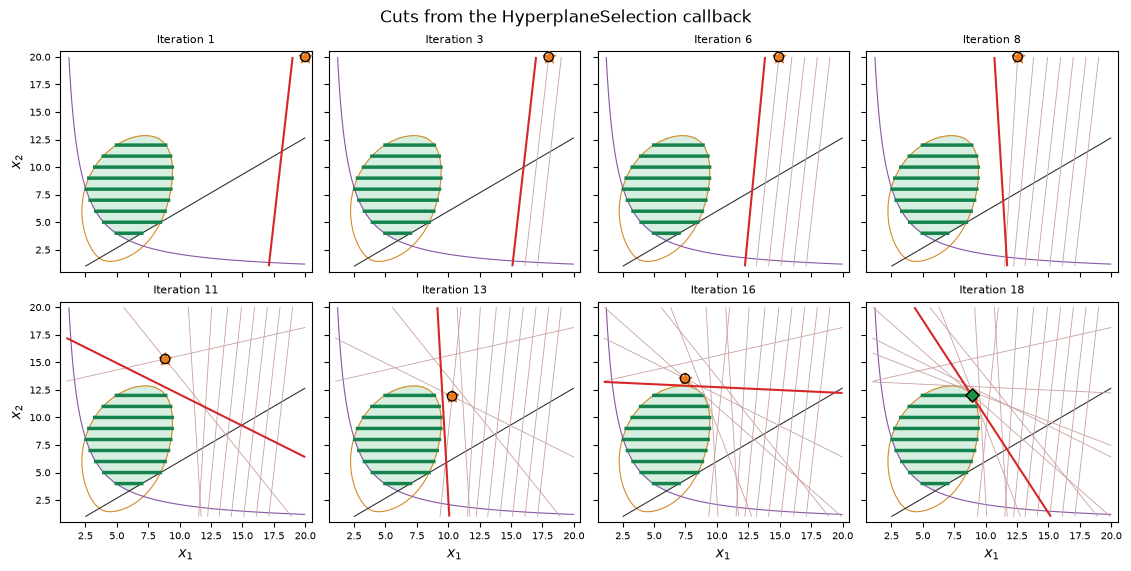

In [25]:
# The feasible region of the problem with x2 continuous, on a grid
X1, X2 = np.meshgrid(np.linspace(1.0, 20.0, 160), np.linspace(1.0, 20.0, 160))
c1 = 0.15*(X1 - 8)**2 + 0.1*(X2 - 6)**2 + 0.025*np.exp(X1)/X2**2 - 5
c2 = 1/X1 + 1/X2 - np.sqrt(X1*X2) + 4
linear = 2*X1 - 3*X2 - 2
feasible = (c1 <= 0) & (c2 <= 0) & (linear <= 0)

# The feasible segments where x2 is integer
segment_x1 = np.linspace(1.0, 20.0, 2000)
segments = []
for value in range(1, 21):
    fulfilled = ((0.15*(segment_x1 - 8)**2 + 0.1*(value - 6)**2 + 0.025*np.exp(segment_x1)/value**2 <= 5)
                 & (1/segment_x1 + 1/value - np.sqrt(segment_x1*value) <= -4) & (2*segment_x1 - 3*value <= 2))
    if fulfilled.any():
        segments.append((value, np.where(fulfilled, segment_x1, np.nan)))

# Eight iterations, evenly spread from the first to the last
iterations = sorted(iteration_log)
shown = sorted({iterations[round(k * (len(iterations) - 1) / 7)] for k in range(8)})
columns = 4
rows = math.ceil(len(shown) / columns)
figure, axes = plt.subplots(rows, columns, figsize=(2.8 * columns, 2.8 * rows), sharex=True, sharey=True,
                            constrained_layout=True)
axes = np.atleast_1d(axes).ravel()

for ax, iteration in zip(axes, shown):
    ax.contourf(X1, X2, feasible, levels=[0.5, 1.5], colors=["#d7efe1"])
    for constraint, color in ((c1, "#d78a27"), (c2, "#8856a7"), (linear, "#333333")):
        ax.contour(X1, X2, constraint, levels=[0], colors=color, linewidths=0.8)
    for value, row in segments:
        ax.plot(row, np.full_like(row, value), color="#16834e", linewidth=2.5)

    for earlier in iterations:
        if earlier > iteration:
            break
        current = earlier == iteration
        for (g1, g2), rhs, (p1, p2) in iteration_log[earlier]["cuts"]:
            ax.contour(X1, X2, g1*X1 + g2*X2 - rhs, levels=[0], colors="#d62728" if current else "#c9a0a0",
                       linewidths=1.5 if current else 0.6)
            if current:
                ax.scatter(p1, p2, marker="*", s=90, color="#ee7b19", zorder=5)
    for p1, p2 in iteration_log[iteration]["points"]:
        ax.scatter(p1, p2, facecolors="none", edgecolors="black", s=45, zorder=6)

    if iteration == iterations[-1]:
        optimum = solver.getPrimalSolution().point
        ax.scatter(optimum[0], optimum[1], marker="D", s=45, color="#159447", edgecolors="black", zorder=7)

    ax.set_title(f"Iteration {iteration}", fontsize=8)
    ax.tick_params(labelsize=7)
    ax.set_xlim(0.5, 20.5)
    ax.set_ylim(0.5, 20.5)

for ax in axes[len(shown):]:
    ax.axis("off")
for ax in axes[::columns]:
    ax.set_ylabel("$x_2$")
for ax in axes[-columns:]:
    ax.set_xlabel("$x_1$")

figure.suptitle("Cuts from the HyperplaneSelection callback")
plt.show()

### 3.7. `InteriorPointSearch`

`InteriorPointSearch` lets you control which interior points are used by the Extended Supporting Hyperplane (ESH) algorithm. The ESH method needs a strictly interior point of the feasible region to generate supporting hyperplanes; normally SHOT finds this point automatically by solving a cutting-plane minimax problem. The callback gives you two complementary powers:

1. **Inspect or replace** the point(s) found by the internal strategy: the callback is called with `ctx.interiorPoints` containing the points the solver just found. Do nothing to keep them, or replace them with `ctx.setInteriorPoints(points)`.

2. **Bypass the internal search entirely** by setting `Dual.ESH.InteriorPoint.Strategy = 1` ("Only external (through callback)"). SHOT then skips the minimax problem and relies completely on the points you set. This is useful when you already know a feasible interior point — for example from a previous solve.

| Field / action | Type | Description |
|---|---|---|
| `ctx.interiorPoints` | `list[list[float]]` | Points found by the internal strategy (empty with `Strategy = 1`), in the variables of the reformulated problem |
| `ctx.setInteriorPoints(points)` | | Replaces the points; each point can be in the variables of the original or the reformulated problem |

The example below demonstrates both powers in a two-phase pattern:

* **Phase 1:** Solve the problem normally and capture the interior point in the callback.
* **Phase 2:** Create a fresh solver with `Dual.ESH.InteriorPoint.Strategy = 1` and set the captured point instead of letting SHOT search for one.

When no interior point is available from a previous solve, one can be found with a small auxiliary problem, as shown after the example.

In [26]:
# Phase 1: solve normally, and capture the interior point SHOT finds
print("Phase 1: solving with the default ESH strategy")

solver1 = SHOTpy.Solver()
solver1.updateSetting("Output.Console.LogLevel", 6)   # Off
assert solver1.setProblem(problem_file)

captured_points = []

def capture_points(ctx):
    captured_points.extend(ctx.interiorPoints)
    print(f"[Phase 1] {len(ctx.interiorPoints)} interior point(s) found internally")
    # No points are set, so SHOT keeps its own

solver1.registerCallback(SHOTpy.CallbackLocation.InteriorPointSearch, capture_points)
assert solver1.solveProblem()

phase1_obj = solver1.getPrimalBound()
print(f"Phase 1 objective: {phase1_obj:.6f}  (known optimum ≈ -20.903615)")
print(f"Captured {len(captured_points)} interior point(s) to reuse in Phase 2\n")

# Phase 2: skip the internal search, and set the captured point instead
print("Phase 2: solving with Dual.ESH.InteriorPoint.Strategy = 1 (only external)")

solver2 = SHOTpy.Solver()
solver2.updateSetting("Output.Console.LogLevel", 6)            # Off
solver2.updateSetting("Dual.ESH.InteriorPoint.Strategy", 1)   # Only external (through callback)
assert solver2.setProblem(problem_file)

def set_points(ctx):
    print(f"[Phase 2] {len(ctx.interiorPoints)} interior point(s) found internally (none, since the search is skipped)")
    ctx.setInteriorPoints(captured_points)

solver2.registerCallback(SHOTpy.CallbackLocation.InteriorPointSearch, set_points)
assert solver2.solveProblem()

phase2_obj = solver2.getPrimalBound()
print(f"Phase 2 objective: {phase2_obj:.6f}")
print(f"Objectives match: {abs(phase2_obj - phase1_obj) < 1e-4}")

Phase 1: solving with the default ESH strategy
╶ Modeling system ────────────────────────────────────────────────────────────────────────────────────────────────────╴

 Modeling system:            OSiL
 Problem read from file:     shot_ex_jogo.osil

- Bound tightening ───────────────────────────────────────────────────────────────────────────────────────────────────╴

 Performing bound tightening on original problem.
  - Bounds for 2 variables tightened in 0.00 s and 5 passes.
  - Objective bounds are: [-23.4282, -4.22729]
Running HiGHS 1.15.1 (git hash: 04024d701): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Rows:           3 lower bounds    less than or equal to       -1e+20 are treated as -Infinity
Rows:           3 lower bounds    less than or equal to       -1e+20 are treated as -Infinity
Running HiGHS 1.15.1 (git hash: 04024d701): Copyright (c) 2026 under MIT licence terms
Includes third-party so

#### Finding an Interior Point with an Auxiliary Problem
When no interior point is available from a previous solve, one can be found by solving a small auxiliary problem: take the original problem, relax the integer variables to continuous ones, add a variable $\mu$, subtract it from every nonlinear constraint, and minimize $\mu$:

$$
\begin{align*}
\text{minimize} \quad & \mu\\
\text{subject to} \quad & 0.15(x_1-8)^2 + 0.1(x_2-6)^2 + \frac{0.025\,e^{x_1}}{x_2^2} - \mu \le 5, \\
& \frac{1}{x_1} + \frac{1}{x_2} - \sqrt{x_1}\,\sqrt{x_2} - \mu \le -4,\\
& 2x_1 -3x_2 \leq  2,\\
& 1 \leq x_1, x_2 \leq 20, \quad -100 \le \mu \le 100.
\end{align*}
$$

If the optimal $\mu^\star < 0$, the solution point is strictly inside all the nonlinear constraints, and can be set in the `InteriorPointSearch` callback. The point is in the variables of the original problem, $x_1$ and $x_2$, without $\mu$.

In [27]:
# Create the auxiliary problem
solver_aux = SHOTpy.Solver()
solver_aux.updateSetting("Output.Console.LogLevel", 6)   # Off

problem_aux = SHOTpy.Problem(solver_aux)
x1 = problem_aux.addVariable("x1", SHOTpy.VariableType.Real, 1.0, 20.0)
x2 = problem_aux.addVariable("x2", SHOTpy.VariableType.Real, 1.0, 20.0)   # relaxed from integer
mu = problem_aux.addVariable("mu", SHOTpy.VariableType.Real, -100.0, 100.0)

problem_aux.setObjective(mu, SHOTpy.ObjectiveDirection.Minimize)
problem_aux.addConstraint(0.15*(x1 - 8)**2 + 0.1*(x2 - 6)**2 + 0.025*SHOTpy.exp(x1)/x2**2 - mu <= 5, "c1")
problem_aux.addConstraint(1/x1 + 1/x2 - x1**0.5 * x2**0.5 - mu <= -4, "c2")
problem_aux.addConstraint(2*x1 - 3*x2 <= 2, "l")
problem_aux.finalize()

assert solver_aux.setProblem(problem_aux)
assert solver_aux.solveProblem()

aux_solution = solver_aux.getPrimalSolution()
interior_point = aux_solution.point[:2]   # without mu
print(f"Optimal mu    : {aux_solution.objValue:.6f}")
print(f"Interior point: x1 = {interior_point[0]:.6f}, x2 = {interior_point[1]:.6f}")
assert aux_solution.objValue < 0   # strictly inside the nonlinear constraints

# Solve the problem with the interior point instead of SHOT's own search
solver3 = SHOTpy.Solver()
solver3.updateSetting("Output.Console.LogLevel", 6)            # Off
solver3.updateSetting("Dual.ESH.InteriorPoint.Strategy", 1)   # Only external (through callback)
assert solver3.setProblem(problem_file)

solver3.registerCallback(SHOTpy.CallbackLocation.InteriorPointSearch,
                         lambda ctx: ctx.setInteriorPoints([interior_point]))
assert solver3.solveProblem()

print(f"Objective     : {solver3.getPrimalBound():.6f}  (known optimum ≈ -20.903615)")
assert abs(solver3.getPrimalBound() + 20.903615) < 1e-3


 Performing bound tightening on original problem.
  - Bounds for 2 variables tightened in 0.00 s and 2 passes.
  - Objective bounds are: [-4.99983, 100]
Running HiGHS 1.15.1 (git hash: 04024d701): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Rows:           3 lower bounds    less than or equal to       -1e+20 are treated as -Infinity
Rows:           3 lower bounds    less than or equal to       -1e+20 are treated as -Infinity
Running HiGHS 1.15.1 (git hash: 04024d701): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Rows:           3 lower bounds    less than or equal to       -1e+20 are treated as -Infinity
Optimal mu    : -3.721615
Interior point: x1 = 7.435539, x2 = 8.550524
╶ Modeling system ────────────────────────────────────────────────────────────────────────────────────────────────────╴

 Modeling system:         

### 3.8. `BoundsUpdated`

`BoundsUpdated` is called after the primal bound, the current dual bound or the global dual bound has changed. Besides the common fields, its context has the bounds before the change (`previousPrimalBound`, `previousDualBound` and `previousGlobalDualBound`) and which of them changed (`primalBoundChanged`, `dualBoundChanged` and `globalDualBoundChanged`).

Unlike `NewPrimalSolution`, it is also called when only the dual bound changes, so it is the callback to use to follow how the bounds converge. The example below records the bounds after every change and plots them; Notebook 3 does the same over time for a larger problem.

In [28]:
# Create solver
solver = SHOTpy.Solver()
solver.updateSetting("Output.Console.LogLevel", 6)   # Off

# Set problem
assert solver.setProblem(problem_file)

# Register callback
bounds_log = []

def record_bounds(ctx):
    bounds_log.append((ctx.iterationNumber, ctx.primalBound, ctx.dualBound,
                       ctx.primalBoundChanged, ctx.dualBoundChanged))

solver.registerCallback(SHOTpy.CallbackLocation.BoundsUpdated, record_bounds)

# Solve
assert solver.solveProblem()

print(f"{len(bounds_log)} bound updates:")
print(f"{'iter':>5}  {'primal bound':>13}  {'dual bound':>11}  changed")
for iteration, primal, dual, primal_changed, dual_changed in bounds_log:
    changed = " and ".join(name for name, flag in (("primal", primal_changed), ("dual", dual_changed)) if flag)
    print(f"{iteration:>5}  {primal:>13.6f}  {dual:>11.6f}  {changed}")

╶ Modeling system ────────────────────────────────────────────────────────────────────────────────────────────────────╴

 Modeling system:            OSiL
 Problem read from file:     shot_ex_jogo.osil

- Bound tightening ───────────────────────────────────────────────────────────────────────────────────────────────────╴

 Performing bound tightening on original problem.
  - Bounds for 2 variables tightened in 0.00 s and 5 passes.
  - Objective bounds are: [-23.4282, -4.22729]
Running HiGHS 1.15.1 (git hash: 04024d701): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Rows:           3 lower bounds    less than or equal to       -1e+20 are treated as -Infinity
Rows:           3 lower bounds    less than or equal to       -1e+20 are treated as -Infinity
Running HiGHS 1.15.1 (git hash: 04024d701): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md f

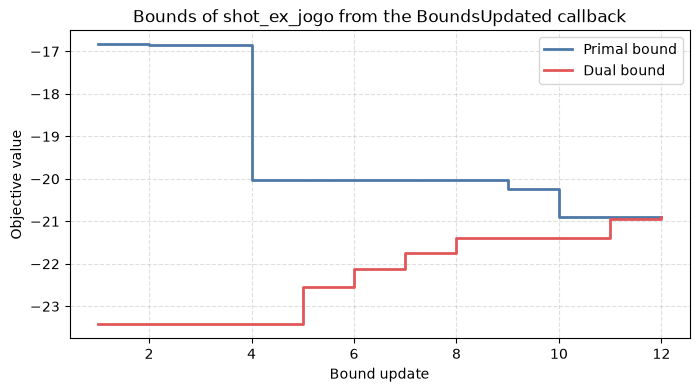

In [29]:
# Plot the bounds after each update; infinite bounds are left out
updates = range(1, len(bounds_log) + 1)
primal = [value if math.isfinite(value) else math.nan for _, value, _, _, _ in bounds_log]
dual = [value if math.isfinite(value) else math.nan for _, _, value, _, _ in bounds_log]

figure, ax = plt.subplots(figsize=(8, 4))
ax.step(updates, primal, where="post", label="Primal bound", color="#4E79A7", linewidth=2)
ax.step(updates, dual, where="post", label="Dual bound", color="#E15759", linewidth=2)
ax.set_xlabel("Bound update")
ax.set_ylabel("Objective value")
ax.set_title("Bounds of shot_ex_jogo from the BoundsUpdated callback")
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend()
plt.show()

### 3.9. `BoundTightening`

`BoundTightening` lets you tighten the bounds of the variables with knowledge that SHOT does not have. It is called in `solver.setProblem()`, so unlike the other callbacks it has to be registered **before** that call. It is called twice: after SHOT's bound tightening of the original problem, and again after that of the reformulated problem, which is created with the bounds of the original problem. `ctx.isReformulatedProblem` tells which call it is.

| Field / action | Description |
|---|---|
| `ctx.problem` | The problem whose bounds can be tightened |
| `ctx.variableLowerBounds` / `ctx.variableUpperBounds` | The bounds of the variables after SHOT's tightening |
| `ctx.setVariableBounds(index, lower, upper)` | Proposes bounds for a variable |

The proposed bounds are intersected with SHOT's bounds, so a bound is never loosened, and the bounds of integer variables are rounded inwards. As for `DualBoundUpdate`, the bounds must not cut off the solutions you want SHOT to find.

The example below uses the objective value of a known solution, $-20.903615$ (Section 3.5). A solution that is at least as good has $-x_1 - x_2 \le -20.903615$, *i.e.*, $x_2 \ge 20.903615 - x_1 \ge 20.903615 - \bar{x}_1$, where $\bar{x}_1$ is the upper bound of $x_1$ after SHOT's tightening of the original problem.

In [30]:
known_objective = -20.903615   # objective value of a known solution, from an earlier solve

# Create solver
solver = SHOTpy.Solver()
solver.updateSetting("Output.Console.LogLevel", 6)   # Off

# Register callback, before setting the problem
event_log = []

def tighten_bounds(ctx):
    lower, upper = ctx.variableLowerBounds, ctx.variableUpperBounds
    name = "reformulated" if ctx.isReformulatedProblem else "original"
    event_log.append(f"{name:>12} problem: x1 in [{lower[0]:.4f}, {upper[0]:.4f}], x2 in [{lower[1]:.0f}, {upper[1]:.0f}]")

    if not ctx.isReformulatedProblem:
        # A solution at least as good as the known one has x2 >= -known_objective - x1
        ctx.setVariableBounds(1, -known_objective - upper[0], upper[1])

solver.registerCallback(SHOTpy.CallbackLocation.BoundTightening, tighten_bounds)

# Set problem
assert solver.setProblem(problem_file)

# Solve
assert solver.solveProblem()

print("Bounds after SHOT's tightening:")
for message in event_log:
    print(f"  {message}")

print(f"\nStatus    : {solver.getModelReturnStatus().name}")
print(f"Objective : {solver.getPrimalBound():.6f}")
assert abs(solver.getPrimalBound() + 20.903615) < 1e-3

╶ Modeling system ────────────────────────────────────────────────────────────────────────────────────────────────────╴

 Modeling system:            OSiL
 Problem read from file:     shot_ex_jogo.osil

- Bound tightening ───────────────────────────────────────────────────────────────────────────────────────────────────╴

 Performing bound tightening on original problem.
  - Bounds for 2 variables tightened in 0.00 s and 5 passes.
  - Bounds for 1 variables tightened by a callback.
  - Objective bounds are: [-23.4282, -13.2273]
Running HiGHS 1.15.1 (git hash: 04024d701): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Rows:           3 lower bounds    less than or equal to       -1e+20 are treated as -Infinity
Rows:           3 lower bounds    less than or equal to       -1e+20 are treated as -Infinity
Running HiGHS 1.15.1 (git hash: 04024d701): Copyright (c) 2026 under MIT licence terms
Includes third-par

## 4. Key Takeaways

### 1. SHOTpy Can Load Problems Directly From Files
No need to rebuild your model in Python from scratch. Point SHOT at a file and let it handle the rest.

### 2. Solver Features and Settings Give You Full Control Over the Solve
There are a lot of different debugging features you can utilize. Moreover, one call — `solver.updateSetting("Option.Name", value)` — puts you in the driver's seat where you can tune what matters most to you over the solve (termination, subsolvers, etc.). Just remember to change the settings before `solver.setProblem()`.

### 3. Callbacks Let You Reach Inside the Solver
Settings cover passive configuration while callbacks go a step further, as you can inject your own logic in the solve: register a function at a `CallbackLocation`, read the state of the solver from its context, and act through the context's methods.

Callbacks are a powerful tool on two fronts: bring domain knowledge directly into the algorithm for fewer iterations and faster solves, or use them as a research sandbox to experiment with custom strategies and probe SHOT's internals in ways that settings alone never could.

### Next Steps
SHOTpy runs inside Python — which means the entire Python ecosystem is at your disposal. In **Notebook 3**, you'll learn how you can use SHOTpy in a Python ecosystem (for example: feed data straight from `pandas`, plot convergence with `matplotlib`, and more). **The solver becomes just one component in a larger workflow rather than a standalone black box.**

That same flexibility extends to research: use callbacks to instrument the solve, collect iteration-level data, test custom cut strategies, or benchmark algorithmic variants — all from a Jupyter notebook. **If you can write it in Python, you can connect it to SHOT.**